In [1]:
import pandas as pd


In [2]:
sales = pd.read_csv("data/king_county_house_sales.csv")
details = pd.read_csv("data/king_county_house_details.csv")

# Left Join: alle Verkäufe behalten, Hausdetails dazuholen
df = sales.merge(
    details,
    left_on="house_id",   # Schlüssel in sales -> verweist auf das Haus
    right_on="id",        # Schlüssel in details
    how="left",
    suffixes=("", "_details"),
)

print(f"combined: {df.shape[0]} rows, {df.shape[1]} columns")
assert len(df) == len(sales), "Es sollte genau eine Zeile pro Verkauf geben"
df.head()

combined: 21597 rows, 23 columns


,date,price,house_id,id,id_details,bedrooms,bathrooms,sqft_living,sqft_lot,floors,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-13,221900.0,7129300520,1,7129300520,3.0,1.00,1180.0,5650.0,1.0,...,7,1180.0,0.0,1955,0.0,98178,47.5112,-122.257,1340.0,5650.0
1,2014-12-09,538000.0,6414100192,2,6414100192,3.0,2.25,2570.0,7242.0,2.0,...,7,2170.0,400.0,1951,1991.0,98125,47.7210,-122.319,1690.0,7639.0
2,2015-02-25,180000.0,5631500400,3,5631500400,2.0,1.00,770.0,10000.0,1.0,...,6,770.0,0.0,1933,NaN,98028,47.7379,-122.233,2720.0,8062.0
3,2014-12-09,604000.0,2487200875,4,2487200875,4.0,3.00,1960.0,5000.0,1.0,...,7,1050.0,910.0,1965,0.0,98136,47.5208,-122.393,1360.0,5000.0
4,2015-02-18,510000.0,1954400510,5,1954400510,3.0,2.00,1680.0,8080.0,1.0,...,8,1680.0,0.0,1987,0.0,98074,47.6168,-122.045,1800.0,7503.0


In [12]:
print(f"{'Quelle':<12} {'Zeilen':>8} {'Spalten':>8}")
print(f"{'sales':<12} {len(sales):>8} {sales.shape[1]:>8}")
print(f"{'details':<12} {len(details):>8} {details.shape[1]:>8}")
print(f"{'merged (df)':<12} {len(df):>8} {df.shape[1]:>8}")

# Left Join: genau eine Zeile pro Verkauf
assert len(df) == len(sales), f"Erwartet {len(sales)} Zeilen, erhalten {len(df)}"

# Verkäufe ohne passende Hausdetails (beim Left Join als NaN in id_details)
print("\nVerkäufe ohne Hausdetails:", df["id_details"].isna().sum())


Quelle         Zeilen  Spalten
sales           21597        4
details         21420       19
merged (df)     21597       23

Verkäufe ohne Hausdetails: 0


In [7]:
df.shape

(21597, 23)

In [13]:
# Eindeutigkeit der Schlüssel in der zusammengeführten Tabelle
check = pd.DataFrame({
    "rows": len(df),
    "unique": df[["id", "house_id"]].nunique(),
    "is_unique": [df["id"].is_unique, df["house_id"].is_unique],
})
check["duplicates"] = check["rows"] - check["unique"]
print(check, "\n")

# Verkaufs-ID muss eindeutig sein: eine Zeile pro Verkauf
assert df["id"].is_unique, "Verkaufs-id ist nicht eindeutig: Der Merge hat Zeilen vervielfacht"

# house_id darf mehrfach vorkommen: Häuser, die mehrmals verkauft wurden
sales_per_house = df["house_id"].value_counts()
print("Häuser mit mehreren Verkäufen:", (sales_per_house > 1).sum())
print(sales_per_house.value_counts().sort_index().rename_axis("Verkäufe pro Haus").rename("Anzahl Häuser"), "\n")

# Beispiel: alle Verkäufe des am häufigsten verkauften Hauses
top_house = sales_per_house.index[0]
df.loc[df["house_id"] == top_house, ["id", "house_id", "date", "price"]]


           rows  unique  is_unique  duplicates
id        21597   21597       True           0
house_id  21597   21420      False         177 

Häuser mit mehreren Verkäufen: 176
Verkäufe pro Haus
1    21244
2      175
3        1
Name: Anzahl Häuser, dtype: int64 



,id,house_id,date,price
17588,17589,795000620,2014-09-24,115000.0
17589,17590,795000620,2014-12-15,124000.0
17590,17591,795000620,2015-03-11,157000.0


### Zu berücksichtigen: Duplikate sollen weder in dem Trainingsset noch in dem Testset vorkommen alternativ Gruppierung anwenden. 

In [11]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

print(f"train: {df_train.shape[0]} rows, test: {df_test.shape[0]} rows")
print("Häuser in Train und Test:", df_train["house_id"].isin(df_test["house_id"]).sum())

train: 17277 rows, test: 4320 rows
Häuser in Train und Test: 64


## 1. Pflicht-Audit der Daten

Verkürzte EDA nach Abschnitt 0, Schritt 1 der Entscheidungsmatrix (`sklearn_decision_matrix_EN.md`): Typen, fehlende Werte, ungültige Einträge, Duplikate, Wertebereiche und Verteilung des Targets. Jeder Befund wird über die Matrix in Abschnitt 1 einer Preprocessing-Entscheidung zugeordnet.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1a. Datentypen

Hat jede Spalte den passenden Typ? `date` wird als Text eingelesen und deshalb in einen Zeitstempel umgewandelt. `zipcode` ist numerisch gespeichert, inhaltlich aber eine **nominale Kategorie**, also später ein Fall für `OneHotEncoder`.

In [4]:
df["date"] = pd.to_datetime(df["date"])
df.dtypes

date             datetime64[us]
price                   float64
house_id                  int64
id                        int64
id_details                int64
bedrooms                float64
bathrooms               float64
sqft_living             float64
sqft_lot                float64
floors                  float64
waterfront              float64
view                    float64
condition                 int64
grade                     int64
sqft_above              float64
sqft_basement           float64
yr_built                  int64
yr_renovated            float64
zipcode                   int64
lat                     float64
long                    float64
sqft_living15           float64
sqft_lot15              float64
dtype: object

## 1b. Fehlende Werte

Anzahl und Anteil der fehlenden Werte pro Spalte. Matrix: numerische Lücken → `SimpleImputer(strategy="median")`, kategoriale Lücken → `SimpleImputer(strategy="most_frequent")`.

In [5]:
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
})
missing[missing["n_missing"] > 0].sort_values("n_missing", ascending=False)

,n_missing,pct_missing
yr_renovated,3848,17.82
waterfront,2391,11.07
sqft_basement,452,2.09
view,63,0.29


## 1c. Ungültige Einträge und Sondermarker

- Welche Werte kommen in den diskreten Spalten vor? Gibt es unplausible Codes?
- `yr_renovated == 0` bedeutet vermutlich „nie renoviert“. Das ist ein **Sondermarker**, kein Jahr. Matrix: in NaN umwandeln oder als eigenes Feature kodieren.
- Konsistenz: Es sollte `sqft_living == sqft_above + sqft_basement` gelten.
- Gibt es Häuser ohne Schlaf- oder Badezimmer?

In [6]:
for col in ["bedrooms", "bathrooms", "floors", "waterfront", "view", "condition", "grade"]:
    print(f"{col:<11}", sorted(df[col].dropna().unique()))

print("\nyr_renovated == 0:", (df["yr_renovated"] == 0).sum(), "Zeilen")

both = df[["sqft_above", "sqft_basement"]].notna().all(axis=1)
mismatch = df.loc[both, "sqft_living"] != df.loc[both, "sqft_above"] + df.loc[both, "sqft_basement"]
print("sqft_living != sqft_above + sqft_basement:", mismatch.sum(), "Zeilen")

print("0 Schlaf- oder Badezimmer:", ((df["bedrooms"] == 0) | (df["bathrooms"] == 0)).sum(), "Zeilen")

bedrooms    [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0)]
bathrooms   [np.float64(0.5), np.float64(0.75), np.float64(1.0), np.float64(1.25), np.float64(1.5), np.float64(1.75), np.float64(2.0), np.float64(2.25), np.float64(2.5), np.float64(2.75), np.float64(3.0), np.float64(3.25), np.float64(3.5), np.float64(3.75), np.float64(4.0), np.float64(4.25), np.float64(4.5), np.float64(4.75), np.float64(5.0), np.float64(5.25), np.float64(5.5), np.float64(5.75), np.float64(6.0), np.float64(6.25), np.float64(6.5), np.float64(6.75), np.float64(7.5), np.float64(7.75), np.float64(8.0)]
floors      [np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5)]
waterfront  [np.float64(0.0), np.float64(1.0)]
view        [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
condition   [np.in

## 1d. Duplikate

- **Exakte Duplikate**, also Zeilen, die bis auf die Verkaufs-`id` identisch sind, wären Erfassungsfehler und werden vor dem Split entfernt.
- **Mehrfachverkäufe** desselben Hauses sind echte Daten. Sie sind trotzdem wichtig für den Split, denn sonst kann dasselbe Haus sowohl in Train als auch in Test landen.

In [8]:
print("Exakte Duplikate (ohne Verkaufs-id):", df.drop(columns="id").duplicated().sum())

sales_per_house = df["house_id"].value_counts()
print("Häuser mit mehreren Verkäufen:", (sales_per_house > 1).sum())
print("\nAnzahl Verkäufe pro Haus:")
print(sales_per_house.value_counts().sort_index())

Exakte Duplikate (ohne Verkaufs-id): 0
Häuser mit mehreren Verkäufen: 176

Anzahl Verkäufe pro Haus:
count
1    21244
2      175
3        1
Name: count, dtype: int64


## 1e. Wertebereiche

Minimum, Maximum und Quantile jeder numerischen Spalte, ohne die IDs. Achte auf unplausible Extremwerte und stark unterschiedliche Skalen. Matrix: unterschiedliche Skalen → `StandardScaler`, Extremwerte → untersuchen und `RobustScaler` vergleichen.

In [9]:
df.drop(columns=["id", "house_id", "id_details"]).describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
date,21597,2014-10-29 04:20:38.171968,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
price,21597.0,540296.573506,78000.0,322000.0,450000.0,645000.0,7700000.0,367368.140101
bedrooms,21597.0,3.371811,1.0,3.0,3.0,4.0,11.0,0.904096
bathrooms,21597.0,2.115826,0.5,1.75,2.25,2.5,8.0,0.768984
sqft_living,21597.0,2080.32185,370.0,1430.0,1910.0,2550.0,13540.0,918.106125
sqft_lot,21597.0,15099.40876,520.0,5040.0,7618.0,10685.0,1651359.0,41412.636876
floors,21597.0,1.494096,1.0,1.0,1.5,2.0,3.5,0.539683
waterfront,19206.0,0.007602,0.0,0.0,0.0,0.0,1.0,0.086858
view,21534.0,0.233863,0.0,0.0,0.0,0.0,4.0,0.765686
condition,21597.0,3.409825,1.0,3.0,3.0,4.0,5.0,0.650546


## 1f. Verteilung des Targets

Wie ist `price` verteilt? Ist der Preis stark rechtsschief, lohnt sich später ein Vergleich mit einem Modell auf `log(price)`. Matrix: rechtsschief → `np.log1p`.

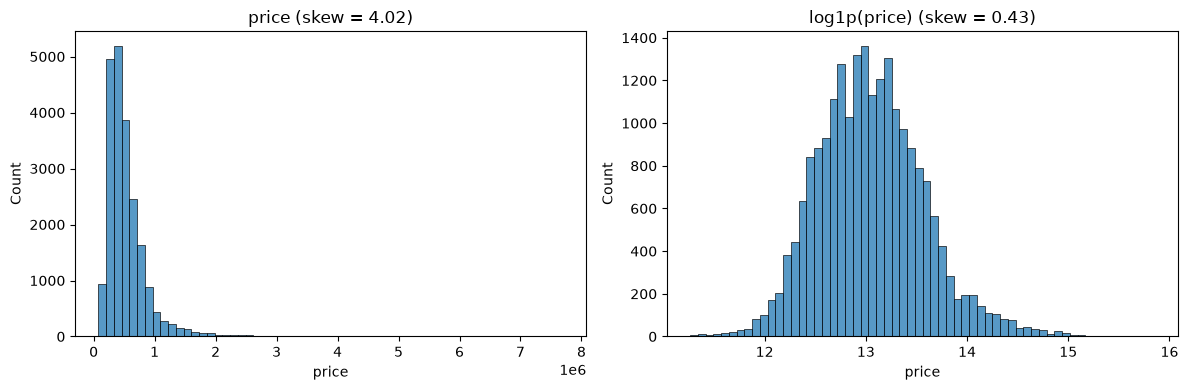

count    2.159700e+04
mean     5.402966e+05
std      3.673681e+05
min      7.800000e+04
25%      3.220000e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=60, ax=axes[0])
axes[0].set_title(f"price (skew = {df['price'].skew():.2f})")
sns.histplot(np.log1p(df["price"]), bins=60, ax=axes[1])
axes[1].set_title(f"log1p(price) (skew = {np.log1p(df['price']).skew():.2f})")
plt.tight_layout()
plt.show()

df["price"].describe()

## Features und Target trennen

`y_train` ist der Preis, also die Größe, die vorhergesagt wird. `X_train` enthält alle übrigen Spalten. Das Testset bleibt unberührt, bis es am Ende genauso vorbereitet und in `X_test` und `y_test` geteilt wird.

In [ ]:
TARGET = "price"

X_train = df_train.drop(columns=TARGET)
y_train = df_train[TARGET]

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")

## 2. Train/Test-Split

Die Daten werden geteilt, **bevor** irgendetwas gelernt wird: Ab hier laufen Exploration, Feature-Auswahl und Tuning nur auf `df_train`. `df_test` bleibt bis zur finalen Evaluation unberührt. `price` bleibt in beiden DataFrames, und `random_state` ist fixiert, damit der Split bei jedem Lauf gleich ist.